# 04 — Segmentation clients | Panier Vert

**Objectif :** regrouper les clients (`user_id` Instacart) en segments homogènes d'après leur comportement d'achat, pour orienter les actions marketing et l'offre des 42 épiceries bio.

**Entrée :** couche Silver Instacart (`orders`, `order_products__prior`, `products`, `departments`).
**Sortie :** table `user_segments` (1 ligne par client) + profil des segments, écrits dans la couche Gold.

**Choix méthodologiques à connaître (à citer dans la soutenance) :**
- Instacart ne contient **aucun prix** : pas de RFM classique. On remplace le *Montant* par la **taille de panier** et on ajoute des variables de comportement (réachat, diversité, part de produits bio, rayons).
- Seules les commandes `prior` servent à décrire le comportement (historique), pour éviter de mélanger avec les commandes `train`.
- Les variables sont asymétriques : transformation `log1p` puis standardisation avant K-Means.
- Le nombre de segments `K` est choisi avec la méthode du coude + silhouette + Davies-Bouldin, **puis validé par lecture métier**, pas uniquement par une métrique.

## 1 — Initialisation

In [52]:
from pathlib import Path
import os, sys, tempfile, warnings
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

# Racine du projet : premier dossier parent contenant "data"
cwd = Path.cwd()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "data").is_dir()), cwd)
SILVER_LOCAL = ROOT / "data" / "silver" / "instacart"
GOLD_LOCAL = ROOT / "data" / "gold"
REPORT_DIR = ROOT / "data" / "reports" / "segmentation"
CACHE_DIR = ROOT / "data" / "cache" / "silver_instacart"
for d in (GOLD_LOCAL, REPORT_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Accès RustFS (comme dans le notebook 03) ; facultatif si les fichiers sont en local
s3 = RUSTFS_BUCKET = None
try:
    sys.path.insert(0, str(ROOT / "src"))
    from panier_vert.storage.rustfs import s3, RUSTFS_BUCKET
    print("RustFS disponible, bucket :", RUSTFS_BUCKET)
except Exception as e:
    print("RustFS indisponible, lecture locale uniquement :", type(e).__name__)

print("Racine :", ROOT)

RustFS disponible, bucket : panier-vert
Racine : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert


In [53]:
def silver_path(name: str) -> Path:
    """Chemin local d'un fichier Silver Instacart.
    Cherche en local ; sinon télécharge depuis RustFS dans un cache (une seule fois)."""
    local = SILVER_LOCAL / name
    if local.exists():
        return local
    cached = CACHE_DIR / name
    if cached.exists():
        return cached
    if s3 is None:
        raise FileNotFoundError(f"{name} introuvable en local et RustFS non disponible.")
    print(f"Téléchargement silver/instacart/{name} ...")
    s3.download_file(RUSTFS_BUCKET, f"silver/instacart/{name}", str(cached))
    return cached

## 2 — Chargement des tables de référence

`orders` (3,4 M lignes) et les référentiels produits/rayons tiennent en mémoire. Le gros fichier `order_products__prior` (32 M lignes) sera lu **par lots** à l'étape suivante.

In [54]:
orders = pd.read_parquet(silver_path("orders.parquet"))
orders = orders[orders["eval_set"] == "prior"].copy()
for c in ["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day"]:
    orders[c] = orders[c].astype("int64")
orders["days_since_prior_order"] = orders["days_since_prior_order"].astype("float64")

products = pd.read_parquet(silver_path("products.parquet"))
departments = pd.read_parquet(silver_path("departments.parquet"))

print(f"Commandes prior : {len(orders):,} | clients : {orders['user_id'].nunique():,}")
print(f"Produits : {len(products):,} | rayons : {len(departments)}")
display(orders.head(3))

Commandes prior : 3,214,874 | clients : 206,209
Produits : 49,688 | rayons : 21


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0


## 3 — Construction des variables par client

Deux familles :
1. **Niveau commande** (depuis `orders`) : nombre de commandes, délai moyen entre commandes, ancienneté, habitudes horaires.
2. **Niveau produit** (depuis `order_products__prior`, par lots) : taille de panier, taux de réachat, diversité, part bio, part des principaux rayons.

*Part bio* = produits dont le nom contient « organic » (approximation, à signaler comme telle).

In [55]:
g = orders.groupby("user_id")
f_orders = pd.DataFrame({
    "nb_orders": g["order_number"].max(),
    "mean_gap_days": g["days_since_prior_order"].mean(),       # NaN sur la 1re commande, ignoré
    "tenure_days": g["days_since_prior_order"].sum(),          # durée d'historique observée
    "weekend_share": g["order_dow"].apply(lambda s: s.isin([0, 1]).mean()),   # jours 0 et 1 = pics de volume (voir note ci-dessous)
    "morning_share": g["order_hour_of_day"].apply(lambda s: s.between(6, 11).mean()),
    "evening_share": g["order_hour_of_day"].apply(lambda s: s.between(18, 23).mean()),
})
display(f_orders.describe().T)

,count,mean,std,min,25%,50%,75%,max
nb_orders,206209.0,15.590367,16.654774,3.0,5.000000,9.000000,19.000000,99.0
mean_gap_days,206209.0,15.209435,7.105277,0.0,9.416667,14.500000,20.285714,30.0
tenure_days,206209.0,156.222595,103.187341,0.0,66.000000,132.000000,237.000000,365.0
weekend_share,206209.0,0.354806,0.218699,0.0,0.211538,0.333333,0.500000,1.0
morning_share,206209.0,0.311936,0.232377,0.0,0.142857,0.285714,0.454545,1.0
evening_share,206209.0,0.183435,0.191472,0.0,0.000000,0.142857,0.285714,1.0


> **Point d'attention — jour de la semaine :** dans Instacart, `order_dow` vaut 0–6 sans que le jour 0 soit officiellement documenté ; l'usage courant est 0 = dimanche, 1 = lundi, mais les volumes (pics aux jours 0 et 1) suggèrent plutôt un week-end. On l'interprète donc comme « jours 0 et 1 = week-end probable ». À mentionner comme hypothèse.

In [56]:
print(orders["order_dow"].value_counts(normalize=True).sort_index().round(3))

order_dow
0    0.173
1    0.173
2    0.137
3    0.128
4    0.125
5    0.133
6    0.130
Name: proportion, dtype: float64


In [57]:
# --- Préparation des correspondances produit -> rayon / bio (tableaux indexés par product_id)
n_prod = int(products["product_id"].max()) + 1
dept_of = np.zeros(n_prod, dtype="int32")
organic_of = np.zeros(n_prod, dtype="int8")
dept_of[products["product_id"].astype(int)] = products["department_id"].astype(int).values
organic_of[products["product_id"].astype(int)] = (
    products["product_name"].astype("string").str.contains("organic", case=False, na=False).astype(int).values
)

# order_id -> user_id (commandes prior uniquement)
order_user = orders.set_index("order_id")["user_id"]

path = silver_path("order_products__prior.parquet")
pf = pq.ParquetFile(path)
print("Lignes dans order_products__prior :", f"{pf.metadata.num_rows:,}")

partials, pair_keys = [], []
DEPT_COLS = None
for i, batch in enumerate(pf.iter_batches(batch_size=1_000_000, columns=["order_id", "product_id", "reordered"])):
    b = batch.to_pandas()
    b["user_id"] = b["order_id"].map(order_user)
    b = b.dropna(subset=["user_id"])
    uid = b["user_id"].astype("int64").values
    pid = b["product_id"].astype("int64").values
    dep = dept_of[pid]
    part = pd.DataFrame({
        "user_id": uid,
        "n_items": 1,
        "n_reordered": b["reordered"].fillna(0).astype("int64").values,
        "n_organic": organic_of[pid],
    })
    dummies = pd.get_dummies(pd.Series(dep, name="dept"), prefix="dept").astype("int32")
    part = pd.concat([part, dummies.reset_index(drop=True)], axis=1)
    partials.append(part.groupby("user_id").sum())
    pair_keys.append(np.unique(uid * 100_000 + pid))
    if (i + 1) % 5 == 0:
        print(f"  lot {i+1} traité")

f_items = pd.concat(partials).groupby(level=0).sum()
all_pairs = np.unique(np.concatenate(pair_keys))
n_distinct = pd.Series(all_pairs // 100_000).value_counts().rename("nb_distinct_products")
f_items = f_items.join(n_distinct)
print("Clients avec produits :", f"{len(f_items):,}")

Lignes dans order_products__prior : 32,434,489
  lot 5 traité
  lot 10 traité
  lot 15 traité
  lot 20 traité
  lot 25 traité
  lot 30 traité
Clients avec produits : 206,209


In [58]:
dept_cols = [c for c in f_items.columns if c.startswith("dept_")]
dept_names = departments.set_index("department_id")["department"].to_dict()

# On garde les 6 rayons les plus achetés comme variables de "part"
top_depts = f_items[dept_cols].sum().sort_values(ascending=False).head(6).index.tolist()
print("Top rayons retenus :", [dept_names.get(int(c.split("_")[1]), c) for c in top_depts])

feat = f_orders.join(f_items[["n_items", "n_reordered", "n_organic", "nb_distinct_products"]], how="inner")
feat["avg_basket_size"] = feat["n_items"] / feat["nb_orders"]
feat["reorder_ratio"] = feat["n_reordered"] / feat["n_items"]
feat["organic_share"] = feat["n_organic"] / feat["n_items"]
feat["product_diversity"] = feat["nb_distinct_products"] / feat["n_items"]
for c in top_depts:
    name = dept_names.get(int(c.split("_")[1]), c).replace(" ", "_")
    feat[f"share_{name}"] = f_items[c] / f_items["n_items"]

feat = feat.drop(columns=["n_items", "n_reordered", "n_organic"])
# 1re commande uniquement => pas de délai : un client a au moins 3 commandes dans Instacart, mais on sécurise
feat["mean_gap_days"] = feat["mean_gap_days"].fillna(feat["mean_gap_days"].median())
print(feat.shape)
display(feat.describe().T.round(3))

Top rayons retenus : ['produce', 'dairy eggs', 'snacks', 'beverages', 'frozen', 'pantry']
(206209, 17)


,count,mean,std,min,25%,50%,75%,max
nb_orders,206209.0,15.590,16.655,3.00,5.000,9.000,19.000,99.00
mean_gap_days,206209.0,15.209,7.105,0.00,9.417,14.500,20.286,30.00
tenure_days,206209.0,156.223,103.187,0.00,66.000,132.000,237.000,365.00
weekend_share,206209.0,0.355,0.219,0.00,0.212,0.333,0.500,1.00
morning_share,206209.0,0.312,0.232,0.00,0.143,0.286,0.455,1.00
evening_share,206209.0,0.183,0.191,0.00,0.000,0.143,0.286,1.00
nb_distinct_products,206209.0,64.536,56.592,1.00,25.000,48.000,86.000,726.00
avg_basket_size,206209.0,9.952,5.864,1.00,5.741,8.933,13.000,70.25
reorder_ratio,206209.0,0.432,0.212,0.00,0.268,0.429,0.596,0.99
organic_share,206209.0,0.272,0.199,0.00,0.087,0.269,0.422,1.00


## 4 — Contrôles qualité des variables

On vérifie : valeurs manquantes, distributions (asymétrie) et corrélations. Les variables très corrélées (|r| > 0,9) apportent la même information et pèsent double dans K-Means : on en retire une.

Valeurs manquantes : 0


,asymétrie
share_beverages,3.06
share_snacks,2.93
share_pantry,2.91
share_frozen,2.68
nb_orders,2.40
nb_distinct_products,1.92
share_dairy_eggs,1.53
avg_basket_size,1.23
evening_share,1.21
morning_share,0.60


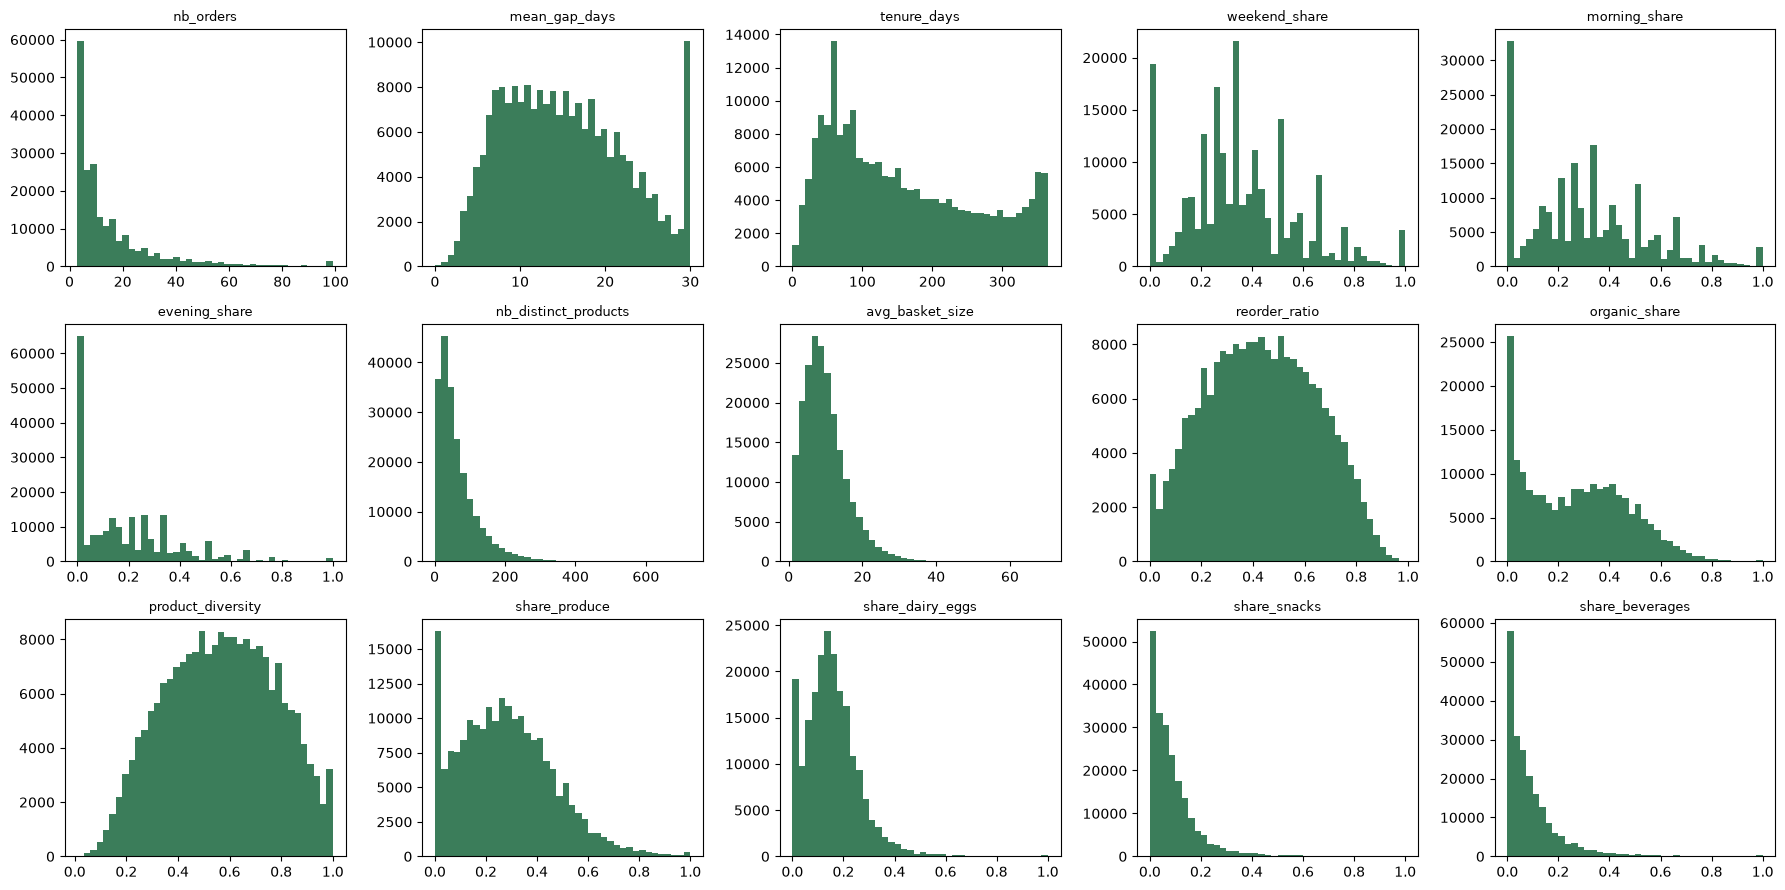

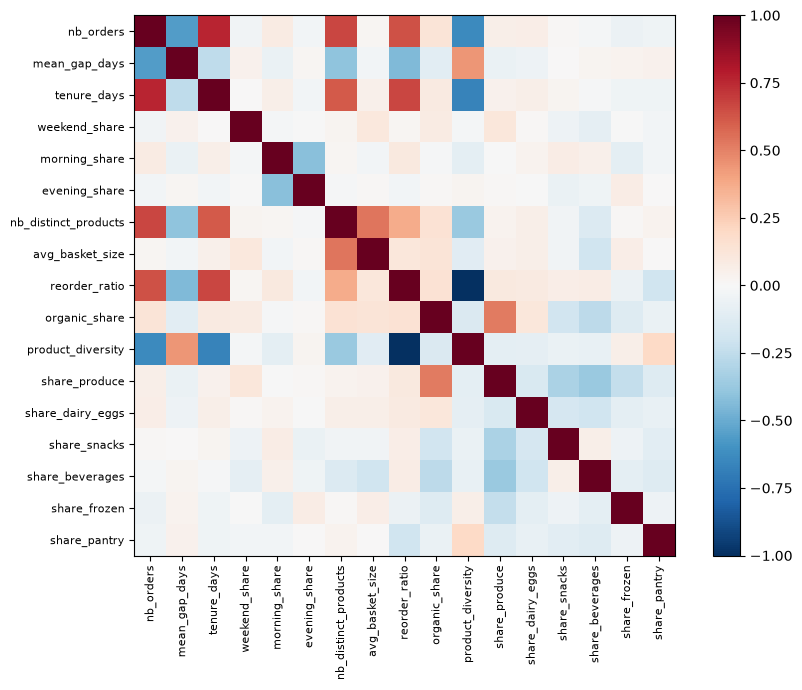

Paires |r| > 0,9 :


,,r
reorder_ratio,product_diversity,-1.0


In [59]:
print("Valeurs manquantes :", int(feat.isna().sum().sum()))
skew = feat.skew().sort_values(ascending=False)
display(skew.round(2).to_frame("asymétrie"))

fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.ravel(), feat.columns):
    ax.hist(feat[c], bins=40, color="#3b7d5a")
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(feat.columns):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(REPORT_DIR / "distributions.png", dpi=120); plt.show()

corr = feat.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.savefig(REPORT_DIR / "correlations.png", dpi=120); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .loc[lambda s: s.abs() > 0.9].sort_values())
print("Paires |r| > 0,9 :"); display(pairs.to_frame("r"))

## 5 — Préparation pour le clustering

- `log1p` sur les variables fortement asymétriques (> 1) ;
- retrait d'une variable de chaque paire trop corrélée (liste `DROP` à ajuster selon le tableau ci-dessus ; par défaut `tenure_days`, redondante avec `nb_orders` × `mean_gap_days`, et `nb_distinct_products`, déjà résumée par `product_diversity` et `avg_basket_size`) ;
- standardisation (K-Means est sensible aux échelles).

In [60]:
print(X.dtypes)

nb_orders           float64
mean_gap_days       float64
weekend_share       float64
morning_share       float64
evening_share       float64
avg_basket_size     float64
reorder_ratio       float64
organic_share       float64
share_produce       float64
share_dairy_eggs    float64
share_snacks        float64
share_beverages     float64
share_frozen        float64
share_pantry        float64
segment               int32
dtype: object


In [61]:
DROP = ["tenure_days", "nb_distinct_products", "product_diversity", "segment", "segment_name"]   # <- à ajuster après lecture des corrélations
X = feat.drop(columns=[c for c in DROP if c in feat.columns]).copy()

skewed = [c for c in X.columns if X[c].skew() > 1]
print("log1p appliqué à :", skewed)
X[skewed] = np.log1p(X[skewed])

scaler = StandardScaler()
Z = scaler.fit_transform(X)
Z = pd.DataFrame(Z, index=X.index, columns=X.columns)
print("Matrice de clustering :", Z.shape)

log1p appliqué à : ['nb_orders', 'evening_share', 'avg_basket_size', 'share_dairy_eggs', 'share_snacks', 'share_beverages', 'share_frozen', 'share_pantry']


Matrice de clustering : (206209, 14)


## 6 — Choix du nombre de segments K

Inertie (coude), silhouette et Davies-Bouldin pour K = 2…10. La silhouette est calculée sur un **échantillon** de 20 000 clients (coût quadratique).

k=2 ok
k=3 ok
k=4 ok
k=5 ok
k=6 ok
k=7 ok
k=8 ok
k=9 ok
k=10 ok


,inertia,silhouette,davies_bouldin
k,,,
2,2554884.655,0.112,2.561
3,2362636.878,0.108,2.429
4,2222112.622,0.098,2.462
5,2126705.923,0.096,2.409
6,2048636.728,0.096,2.284
7,1973089.400,0.102,2.165
8,1906573.234,0.100,2.128
9,1852319.114,0.098,2.085
10,1802450.841,0.088,2.101


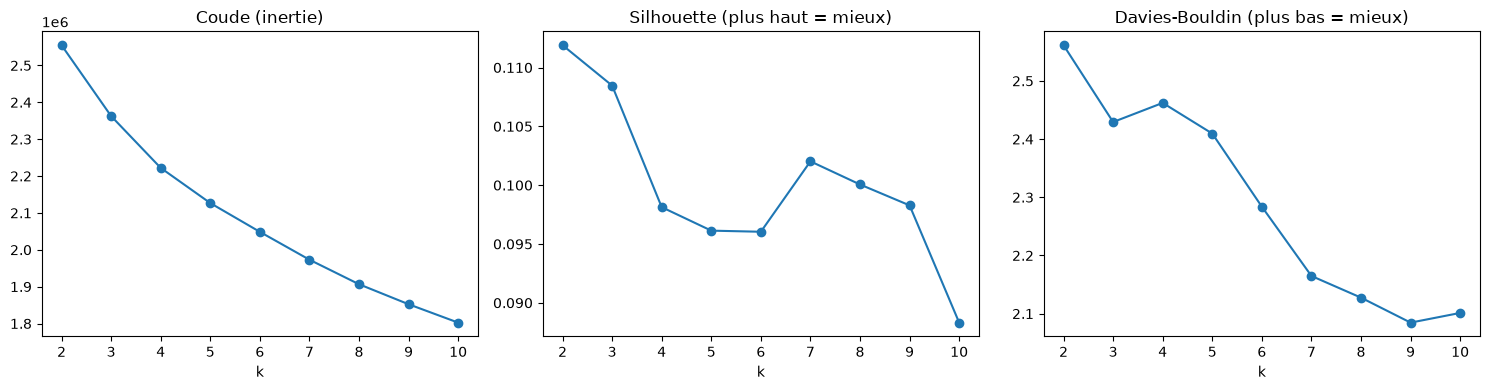

In [62]:
from sklearn import config_context

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(Z), size=min(10_000, len(Z)), replace=False)
Zs = Z.values[sample_idx]

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(Z.values)
    labels_s = km.predict(Zs)
    # working_memory (en Mo) force sklearn à calculer les distances par petits blocs
    with config_context(working_memory=64):
        sil = silhouette_score(Zs, labels_s)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": sil,
        "davies_bouldin": davies_bouldin_score(Zs, labels_s),
    })
    print(f"k={k} ok")
sel = pd.DataFrame(rows).set_index("k")
display(sel.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sel["inertia"].plot(marker="o", ax=axes[0], title="Coude (inertie)")
sel["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette (plus haut = mieux)")
sel["davies_bouldin"].plot(marker="o", ax=axes[2], title="Davies-Bouldin (plus bas = mieux)")
plt.tight_layout(); plt.savefig(REPORT_DIR / "choix_k.png", dpi=120); plt.show()

## 7 — Modèle final et stabilité

Choisir `K` en regardant les trois courbes **et** l'interprétabilité (4 à 6 segments exploitables par le marketing, c'est généralement le bon compromis). Un bon clustering doit aussi être **stable** : on le réentraîne avec d'autres graines et on mesure l'accord (ARI, 1 = identique).

In [63]:
feat = feat.drop(columns=["segment", "segment_name"], errors="ignore")
K = 4   # <- à fixer après lecture des courbes de la section 6

km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z.values)
feat["segment"] = km.labels_
X["segment"] = km.labels_

# Stabilité : ARI entre le modèle de référence et 5 autres graines
ari = []
for seed in range(1, 6):
    other = KMeans(n_clusters=K, n_init=10, random_state=seed).fit(Z.values)
    ari.append(adjusted_rand_score(km.labels_, other.labels_))
print("ARI vs autres graines :", np.round(ari, 3), "| moyenne", round(float(np.mean(ari)), 3))
print("\nTaille des segments :")
display(feat["segment"].value_counts(normalize=True).sort_index().round(3).to_frame("part"))

ARI vs autres graines : [0.983 0.994 0.974 0.98  0.973] | moyenne 0.981

Taille des segments :


,part
segment,
0,0.294
1,0.286
2,0.122
3,0.298


## 8 — Profil et interprétation des segments

Le tableau d'**indice** compare la moyenne de chaque segment à la moyenne globale (100 = moyenne). Au-dessus de ~120 ou en dessous de ~80, la variable caractérise le segment.

,n_clients,part_%,nb_orders,mean_gap_days,tenure_days,weekend_share,morning_share,evening_share,nb_distinct_products,avg_basket_size,reorder_ratio,organic_share,product_diversity,share_produce,share_dairy_eggs,share_snacks,share_beverages,share_frozen,share_pantry
segment,,,,,,,,,,,,,,,,,,,
0,60528,29.4,7.817,17.797,111.111,0.325,0.234,0.240,49.554,10.180,0.302,0.139,0.698,0.161,0.156,0.086,0.087,0.119,0.087
1,58979,28.6,7.134,18.101,106.312,0.415,0.316,0.164,44.330,10.317,0.339,0.402,0.661,0.430,0.153,0.055,0.051,0.048,0.052
2,25242,12.2,12.546,16.140,146.384,0.287,0.429,0.107,30.397,5.390,0.458,0.119,0.542,0.113,0.094,0.202,0.287,0.033,0.034
3,61460,29.8,32.611,9.504,252.587,0.354,0.338,0.178,112.704,11.249,0.639,0.343,0.361,0.318,0.186,0.079,0.072,0.063,0.054


,nb_orders,mean_gap_days,tenure_days,weekend_share,morning_share,evening_share,nb_distinct_products,avg_basket_size,reorder_ratio,organic_share,product_diversity,share_produce,share_dairy_eggs,share_snacks,share_beverages,share_frozen,share_pantry
segment,,,,,,,,,,,,,,,,,
0,50.0,117.0,71.0,92.0,75.0,131.0,77.0,102.0,70.0,51.0,123.0,58.0,100.0,96.0,89.0,167.0,143.0
1,46.0,119.0,68.0,117.0,101.0,89.0,69.0,104.0,78.0,148.0,116.0,154.0,98.0,62.0,53.0,67.0,86.0
2,80.0,106.0,94.0,81.0,137.0,58.0,47.0,54.0,106.0,44.0,95.0,41.0,60.0,227.0,297.0,47.0,56.0
3,209.0,62.0,162.0,100.0,108.0,97.0,175.0,113.0,148.0,126.0,64.0,114.0,119.0,88.0,75.0,88.0,89.0


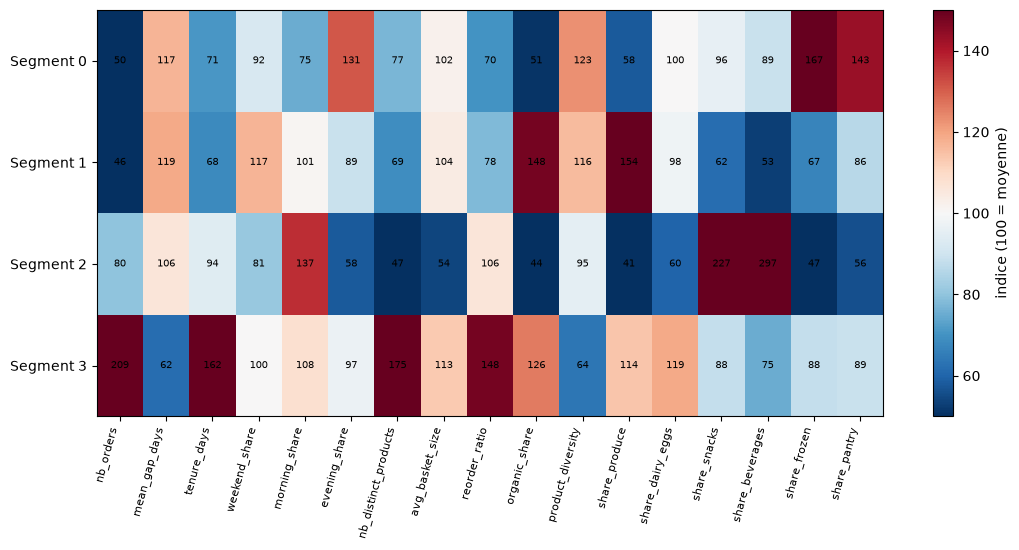

Segment 0 (60,528 clients) : organic_share (-0.7σ), share_produce (-0.6σ), reorder_ratio (-0.6σ), share_frozen (+0.6σ)
Segment 1 (58,979 clients) : share_produce (+0.8σ), organic_share (+0.7σ), nb_orders (-0.6σ), reorder_ratio (-0.4σ)
Segment 2 (25,242 clients) : share_beverages (+1.6σ), share_snacks (+1.1σ), avg_basket_size (-1.0σ), share_produce (-0.9σ)
Segment 3 (61,460 clients) : nb_orders (+1.1σ), reorder_ratio (+1.0σ), mean_gap_days (-0.8σ), organic_share (+0.4σ)


In [64]:
profile = feat.groupby("segment").mean()
profile.insert(0, "n_clients", feat["segment"].value_counts().sort_index())
profile.insert(1, "part_%", (100 * profile["n_clients"] / len(feat)).round(1))
display(profile.round(3))

index_tbl = (feat.drop(columns="segment").groupby(feat["segment"]).mean() / feat.drop(columns="segment").mean() * 100).round(0)
display(index_tbl)
fig, ax = plt.subplots(figsize=(11, 0.9 * len(index_tbl) + 2))
im = ax.imshow(index_tbl.values, cmap="RdBu_r", vmin=50, vmax=150, aspect="auto")
ax.set_xticks(range(index_tbl.shape[1])); ax.set_xticklabels(index_tbl.columns, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(index_tbl.shape[0])); ax.set_yticklabels([f"Segment {i}" for i in index_tbl.index])
for (r, c_), v in np.ndenumerate(index_tbl.values):
    ax.text(c_, r, int(v), ha="center", va="center", fontsize=7)
plt.colorbar(im, label="indice (100 = moyenne)"); plt.tight_layout()
plt.savefig(REPORT_DIR / "indice_segments.png", dpi=120); plt.show()

# Aide à la lecture : variables les plus distinctives par segment (écart en écarts-types)
zprof = Z.groupby(feat["segment"]).mean()
for s in zprof.index:
    top = zprof.loc[s].sort_values(key=abs, ascending=False).head(4)
    desc = ", ".join(f"{v} ({'+' if x > 0 else '-'}{abs(x):.1f}σ)" for v, x in top.items())
    print(f"Segment {s} ({int(profile.loc[s, 'n_clients']):,} clients) : {desc}")

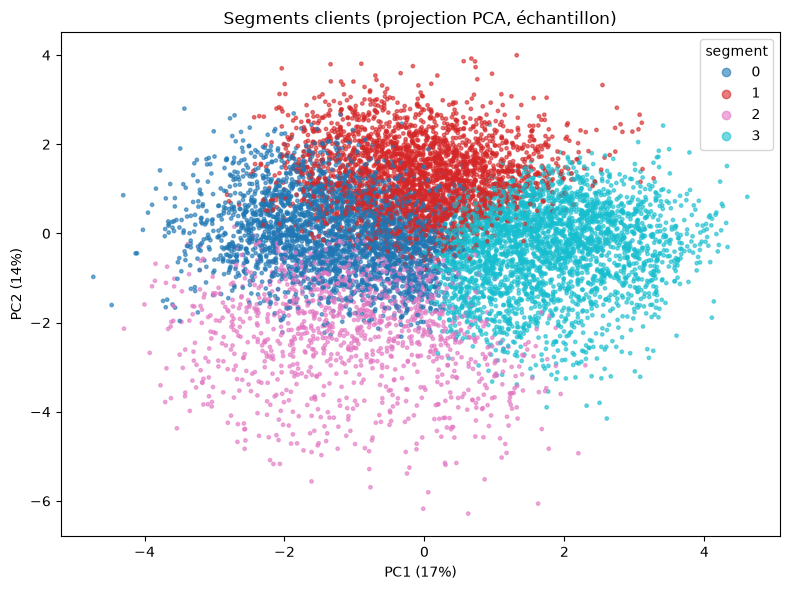

In [65]:
# Visualisation 2D (PCA) sur un échantillon
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z.values)
P = pca.transform(Zs)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(P[:, 0], P[:, 1], c=feat["segment"].values[sample_idx], cmap="tab10", s=6, alpha=0.6)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Segments clients (projection PCA, échantillon)")
ax.legend(*sc.legend_elements(), title="segment")
plt.tight_layout(); plt.savefig(REPORT_DIR / "segments_pca.png", dpi=120); plt.show()

## 9 — Nommer les segments

À compléter **à la main** après lecture du profil (section 8). Un nom métier + une action marketing par segment : c'est ce que le jury attend. Exemples de pistes de lecture : gros paniers espacés, petits paniers fréquents, clients très fidèles aux mêmes produits (réachat élevé), amateurs de bio / de frais, explorateurs (diversité élevée).

In [66]:
SEGMENT_NAMES = {
    0: "Occasionnels épicerie & surgelés",
    1: "Occasionnels bio & frais",
    2: "Dépanneurs boissons & snacks",
    3: "Fidèles routiniers",
}
feat["segment_name"] = feat["segment"].map(lambda s: SEGMENT_NAMES.get(s, f"Segment {s}"))
display(feat["segment_name"].value_counts().to_frame("clients"))

,clients
segment_name,
Fidèles routiniers,61460
Occasionnels épicerie & surgelés,60528
Occasionnels bio & frais,58979
Dépanneurs boissons & snacks,25242


## 10 — Export Gold

Écriture de la table clients → segments (Parquet) et du profil (CSV). Envoi optionnel vers RustFS (`gold/instacart/`).

In [67]:
UPLOAD_TO_RUSTFS = False   # passer à True pour pousser dans le bucket

out = feat.reset_index().rename(columns={"index": "user_id"})
out_path = GOLD_LOCAL / "user_segments.parquet"
out.to_parquet(out_path, index=False)
profile.round(4).to_csv(REPORT_DIR / "profil_segments.csv")
sel.round(4).to_csv(REPORT_DIR / "choix_k.csv")
print("Écrit :", out_path, f"({len(out):,} lignes)")

if UPLOAD_TO_RUSTFS and s3 is not None:
    s3.upload_file(str(out_path), RUSTFS_BUCKET, "gold/instacart/user_segments.parquet")
    s3.upload_file(str(REPORT_DIR / "profil_segments.csv"), RUSTFS_BUCKET, "gold/instacart/profil_segments.csv")
    print("Envoyé dans RustFS : gold/instacart/")

Écrit : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert\data\gold\user_segments.parquet (206,209 lignes)


## 11 — Limites et suites

- Pas de prix dans Instacart : la segmentation décrit des **comportements**, pas une valeur monétaire.
- La part bio est une approximation par le nom du produit ; l'appariement avec Open Food Facts (J2) pourrait l'affiner (Nutri-Score, NOVA) et ouvrir une segmentation **produits**.
- Alternatives à comparer si le temps le permet : GMM, classification hiérarchique (sur échantillon), DBSCAN.
- Industrialisation (jalon MLOps) : sauvegarder `scaler` et `km` (joblib), versionner avec DVC/MLflow, et prévoir une fonction `assign_segment(user_features)` pour les nouveaux clients.